        # Cognitive Science (1204 427) — Lab 09
        ## Category Learning: Prototype versus Exemplar

        **ระดับ:** ปริญญาตรี  
        **เวลาที่แนะนำ:** 150–180 นาที  
        **รูปแบบ:** งานเดี่ยวบน Google Colab/Jupyter Notebook  
        **แพ็กเกจหลัก:** `numpy, pandas, matplotlib, scikit-learn`

        ### แนวคิดสำคัญ

        Prototype Model แทน Category ด้วยตัวแทนเฉลี่ย ส่วน Exemplar Model เปรียบเทียบสิ่งใหม่กับตัวอย่างที่เคยพบ การทดลองนี้แปลงสองแนวคิดเป็น Classifiers ที่ตรวจสอบได้

        ### วัตถุประสงค์

        สร้างข้อมูลหมวดหมู่สองมิติ เปรียบเทียบ Prototype Classifier กับ k-Nearest Exemplar และวิเคราะห์กรณีที่แต่ละแนวคิดทำงานต่างกัน

        ### งานที่ต้องทำ

        1. สร้าง Training/Test Data แยกกัน
2. คำนวณ Category Prototypes
3. สร้าง Prototype และ Exemplar Classifiers
4. เปรียบเทียบ Accuracy และ Confusion Matrices
5. Required Extension: ทดลอง k = 1, 3, 5, 9

        > ไปที่ [Google Colab](https://colab.research.google.com) แล้วเลือก **File → Upload notebook** เพื่อเปิดไฟล์นี้


## ข้อมูลนิสิตและคำชี้แจง

- ชื่อ–สกุล: วชิรวิทย์ วงค์แสง
- รหัสนิสิต: 67011212055
- กลุ่มเรียน: 1

1. เปลี่ยน `STUDENT_ID` เป็นรหัสนิสิตของตนเองก่อนรันโปรแกรม
2. รหัส 4 หลักสุดท้ายใช้เป็น Random Seed ทำให้ข้อมูลแต่ละคนแตกต่างกัน
3. รันเซลล์จากบนลงล่างและเก็บ Output ไว้ในไฟล์ที่ส่ง
4. ทุกกราฟต้องมีชื่อกราฟ ชื่อแกน หน่วย และคำอธิบาย
5. ห้ามสรุปผลเกินกว่าหลักฐานจากข้อมูลหรืออ้างว่าข้อมูลจำลองเป็นข้อมูลมนุษย์จริง
6. ส่งไฟล์ `.ipynb` และ `.pdf` โดยตั้งชื่อ `StudentID_LabXX.ipynb`


In [1]:
STUDENT_ID = 67011212055  # รหัสนิสิต: วชิรวิทย์ วงค์แสง
sid = str(STUDENT_ID).strip()
if not sid.isdigit() or len(sid) < 4:
    raise ValueError("STUDENT_ID ต้องเป็นตัวเลขอย่างน้อย 4 หลัก")
seed = int(sid[-4:])
print(f"Student ID: {sid} | Random seed: {seed}")


Student ID: 67011212055 | Random seed: 2055


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

rng = np.random.default_rng(seed + 90)

def make_category(center, n, spread, label):
    x = rng.normal(center[0], spread[0], n)
    y = rng.normal(center[1] + 0.35 * (x - center[0]), spread[1], n)
    return pd.DataFrame({"feature_1": x, "feature_2": y, "category": label})

train = pd.concat([
    make_category((-1.2, -0.7), 70, (1.0, 0.75), "A"),
    make_category((1.2, 0.7), 70, (1.0, 0.75), "B"),
], ignore_index=True).sample(frac=1, random_state=seed)
test = pd.concat([
    make_category((-1.2, -0.7), 180, (1.15, 0.9), "A"),
    make_category((1.2, 0.7), 180, (1.15, 0.9), "B"),
], ignore_index=True).sample(frac=1, random_state=seed + 1)
display(train.head())


,feature_1,feature_2,category
94,2.165959,1.530648,B
13,-0.887194,-0.586304,A
52,-0.467566,-0.066547,A
9,-2.537312,-1.572938,A
11,-2.351943,-1.315245,A


In [3]:
features = ["feature_1", "feature_2"]
prototypes = train.groupby("category")[features].mean()

def prototype_predict(frame):
    result = []
    for point in frame[features].to_numpy():
        distances = np.sqrt(((prototypes.to_numpy() - point) ** 2).sum(axis=1))
        result.append(prototypes.index[np.argmin(distances)])
    return np.array(result)

prototype_pred = prototype_predict(test)
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(train[features], train["category"])
exemplar_pred = knn.predict(test[features])

result = pd.DataFrame({
    "model": ["Prototype", "Exemplar k=3"],
    "accuracy": [accuracy_score(test.category, prototype_pred), accuracy_score(test.category, exemplar_pred)],
})
display(prototypes.round(3)); display(result.round(4))
print("Prototype confusion matrix:")
print(confusion_matrix(test.category, prototype_pred, labels=["A", "B"]))
print("Exemplar confusion matrix:")
print(confusion_matrix(test.category, exemplar_pred, labels=["A", "B"]))


,feature_1,feature_2
category,,
A,-1.017,-0.633
B,1.271,0.670


,model,accuracy
0,Prototype,0.8306
1,Exemplar k=3,0.8194


Prototype confusion matrix:
[[151  29]
 [ 32 148]]
Exemplar confusion matrix:
[[152  28]
 [ 37 143]]


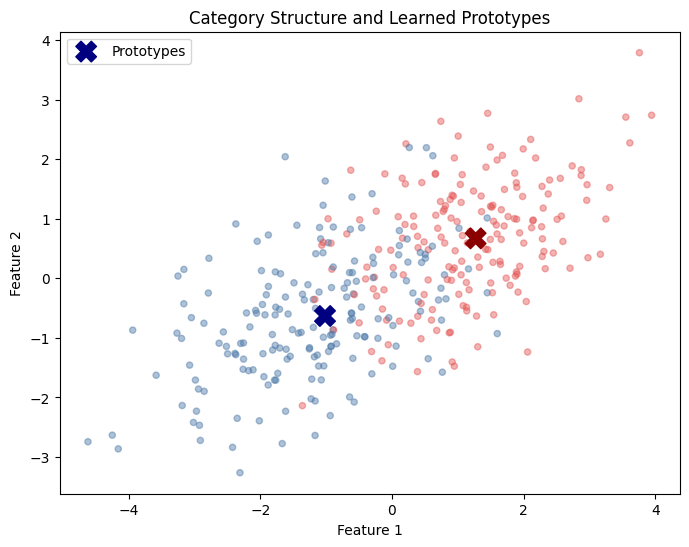

In [4]:
colors = test.category.map({"A": "#4c78a8", "B": "#e45756"})
plt.figure(figsize=(8, 6))
plt.scatter(test.feature_1, test.feature_2, c=colors, alpha=0.45, s=20)
plt.scatter(prototypes.feature_1, prototypes.feature_2, c=["navy", "darkred"], marker="X", s=220, label="Prototypes")
plt.xlabel("Feature 1"); plt.ylabel("Feature 2")
plt.title("Category Structure and Learned Prototypes")
plt.legend(); plt.show()


## Required Extension

ทดลอง Exemplar Model ด้วย `k = 1, 3, 5, 9` บันทึก Train Accuracy และ Test Accuracy แล้วอธิบายผลของ Model Complexity


,k,train_accuracy,test_accuracy
0,1,1.000,0.800
1,3,0.893,0.819
2,5,0.886,0.839
3,9,0.871,0.831


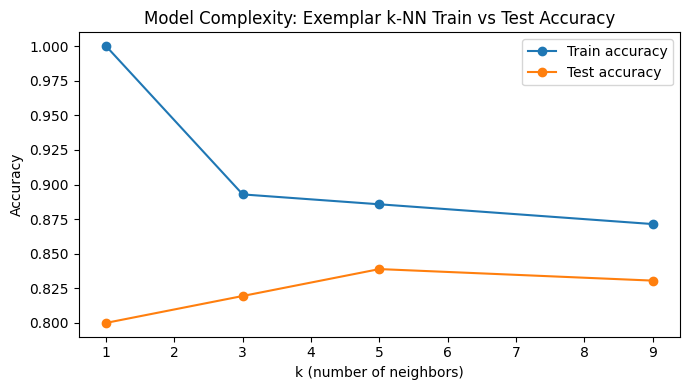

In [5]:
# ===== Required Extension: ทดลอง Exemplar Model ด้วย k = 1, 3, 5, 9 =====
acc_rows = []
for k in [1, 3, 5, 9]:
    knn_k = KNeighborsClassifier(n_neighbors=k)
    knn_k.fit(train[features], train["category"])
    train_acc = accuracy_score(train["category"], knn_k.predict(train[features]))
    test_acc = accuracy_score(test["category"], knn_k.predict(test[features]))
    acc_rows.append([k, train_acc, test_acc])

accuracy_by_k = pd.DataFrame(acc_rows, columns=["k", "train_accuracy", "test_accuracy"])
display(accuracy_by_k.round(3))

plt.figure(figsize=(7, 4))
plt.plot(accuracy_by_k["k"], accuracy_by_k["train_accuracy"], marker="o", label="Train accuracy")
plt.plot(accuracy_by_k["k"], accuracy_by_k["test_accuracy"], marker="o", label="Test accuracy")
plt.xlabel("k (number of neighbors)")
plt.ylabel("Accuracy")
plt.title("Model Complexity: Exemplar k-NN Train vs Test Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


## คำถามวิเคราะห์ Lab 09

**1. Prototype และ Exemplar Models ใช้ตัวแทนความรู้ต่างกันอย่างไร**

Prototype เก็บแค่ "ค่าเฉลี่ย" ของแต่ละหมวดเป็นตัวแทนเดียว แล้วเทียบของใหม่กับ prototype ส่วน Exemplar (k-NN) จำตัวอย่างที่เคยเห็นทั้งหมดแล้วเทียบของใหม่กับเพื่อนบ้านที่ใกล้ที่สุด คือ prototype สรุปเป็นแก่น ส่วน exemplar จำรายละเอียดทุกอัน

**2. Model ใดมี Test Accuracy สูงกว่าในข้อมูลนี้**

ใกล้กันมากครับ Prototype ~0.83 กับ Exemplar k=3 ~0.82 พอๆ กันเพราะข้อมูลสองหมวดเป็นก้อนกลมๆ แยกกันชัด (linearly separable) prototype เลยพอเพียง ไม่ได้แพ้ exemplar

**3. ค่า k ส่งผลต่อ Overfitting/Underfitting อย่างไร**

k=1 train accuracy = 1.0 แต่ test ต่ำสุด (~0.80) คือ overfit จำ noise พอเพิ่ม k (5, 9) เส้นแบ่งเรียบขึ้น test accuracy ดีขึ้น (~0.84) แต่ k มากไปก็เริ่ม underfit ค่า k กลางๆ เลยสมดุลสุด

**4. Confusion Matrix เปิดเผยสิ่งใดที่ Accuracy ไม่บอก**

มันบอกว่าพลาดไปทางไหน เช่นเอา A ไปทายเป็น B กี่ตัว กับ B เป็น A กี่ตัว ถ้า error เอนไปข้างเดียวแปลว่าโมเดลลำเอียงเข้าหมวดนึง ส่วน accuracy บอกแค่ % ถูกรวมๆ ไม่เห็น pattern ของความผิด

**5. ข้อมูลสองมิตินี้จำลอง Category Learning ของมนุษย์ได้ไม่ครบในด้านใด**

ของจริงคนใช้ feature เยอะกว่า 2 มิติ, ให้น้ำหนัก feature ไม่เท่ากัน, เรียนรู้ทีละตัวอย่าง (online) และมีเรื่อง typicality/ความคุ้น ส่วนข้อมูลนี้เป็น gaussian สองก้อนสวยๆ feature เท่ากัน ไม่มีการเรียนแบบค่อยเป็นค่อยไป เลยง่ายกว่าจริง

## Reflection และ Checklist ก่อนส่ง

**Reflection:**

ส่วนที่ยากสุดคือ Required Extension ตอนดูผลของ k ตอนแรกงงว่าทำไม k=1 train ได้ 100% แต่ test แย่สุด พอคิดตามถึงเข้าใจว่ามันจำทุกจุดรวม noise (overfit) พอเพิ่ม k เส้นแบ่งเรียบขึ้น test เลยดีขึ้น เห็น bias-variance trade-off ชัดดี

สิ่งที่เชื่อมกับ cognitive science คือมันแทนสองทฤษฎีความจำหมวดหมู่เป็นโค้ดที่ตรวจสอบได้ prototype = จำแก่น, exemplar = จำตัวอย่าง แล้วเทียบกันได้จริง เห็นว่าในข้อมูลง่ายๆ สองแบบพอกัน

ถ้าทำซ้ำ อยากลองข้อมูลที่หมวดซ้อนทับหรือรูปร่างไม่กลม เพื่อดูว่า exemplar จะเอาชนะ prototype ไหม และเพิ่มมิติ feature ให้ใกล้ความจริงของการเรียนหมวดหมู่ของคนมากขึ้น

### เกณฑ์ประเมิน

| ด้าน | คะแนน |
|---|---:|
| ความถูกต้องของโปรแกรมและผลลัพธ์ | 35 |
| กระบวนการวิเคราะห์และความสมเหตุสมผล | 20 |
| กราฟ ตาราง และการสื่อสารผล | 15 |
| การตีความตามหลัก Cognitive Science | 20 |
| คุณภาพโค้ดและ Reflection | 10 |
| **รวม** | **100** |

- [x] เปลี่ยน `STUDENT_ID` แล้ว
- [x] รันทุกเซลล์โดยไม่มี Error
- [x] ทำ Required Extension สำเร็จ
- [x] ตอบคำถามทุกข้อด้วยถ้อยคำของตนเอง
- [x] ตรวจไฟล์ `.ipynb` และ `.pdf` ก่อนส่ง
